In [ ]:
pip install SALib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 758.0/758.0 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 6.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.3/115.3 kB 3.8 MB/s eta 0:00:00


<ipython-input-3-e9662516f763>:18: DeprecationWarning: `salib.sample.saltelli` will be removed in SALib 1.5. Please use `salib.sample.sobol`
  param_values = saltelli.sample(problem, 1000)
/usr/local/lib/python3.10/dist-packages/SALib/sample/saltelli.py:109: UserWarning: 
        Convergence properties of the Sobol' sequence is only valid if
        `N` (1000) is equal to `2^n`.
        
  warnings.warn(msg)


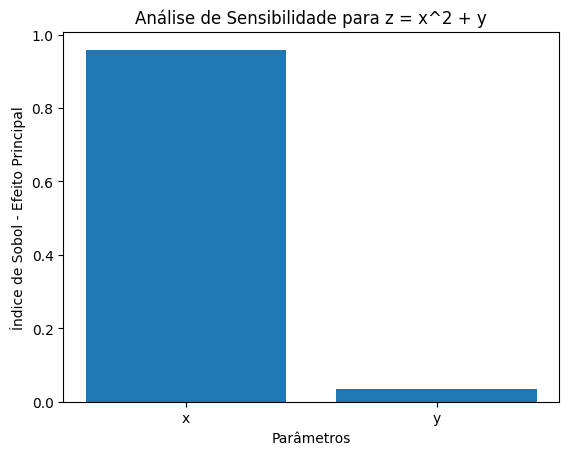

In [ ]:
import numpy as np
from SALib.sample import saltelli
from SALib.analyze import sobol
import matplotlib.pyplot as plt

# Definição da função para análise de sensibilidade
# X[:, 0]**2 + X[:, 1] para x^2+y
def custom_function(X):
    T = X[:, 1]

    e = 1.602e-19
    k_B = 1.38065e-23
    N_A = 6.02e23
    eps_0 = 8.85e-11
    eps_3 = 80
    I = varia

    psi_ro = e * psi_0 / (k_B * T)
    gamma = ( np.exp(psi_ro/2) - 1 ) / ( np.exp(psi_ro/2) + 1 )
    kappa = ( k_B*eps_3*eps_0*T / (2*N_A*I*e**2) )**(-0.5)

    psi = (2*k_B*T/e) * np.log((1+gamma*np.exp(-kappa*x))/(1-gamma*np.exp(-kappa*x)))


    return X[:, 0]**2 + X[:, 1]

# Definição do problema para a análise de sensibilidade
problem = {
    'num_vars': 2,
    'names': ['x', 'y'],
    'bounds': [[-10, 10], [-10, 10]]
}

# Gerar amostras
param_values = saltelli.sample(problem, 1000)

# Avaliar a função
Y = custom_function(param_values)

# Realizar a análise de sensibilidade de Sobol
Si = sobol.analyze(problem, Y)

# Gráfico de barras dos índices de Sobol
plt.bar(problem['names'], Si['S1'])
plt.xlabel('Parâmetros')
plt.ylabel('Índice de Sobol - Efeito Principal')
plt.title('Análise de Sensibilidade para z = x^2 + y')
plt.show()
